In [ ]:
# /code to extract the info from the models results from a local folder 

In [15]:
import pandas as pd 

In [16]:
import os
import re
import ast
import pandas as pd

def extract_settings_from_folder(folder_name):
    settings = {}
    parts = folder_name.split('__')
    for part in parts:
        key, value = part.split('_', 1)
        settings[key] = value
    return settings

def extract_top_model_results(summary_path):
    with open(summary_path, 'r') as f:
        content = f.read()
    
    # Extract the dictionary-like string
    match = re.search(r'\{.*\}', content, re.DOTALL)
    if match:
        try:
            # Use ast.literal_eval instead of json.loads for more flexible parsing
            result_dict = ast.literal_eval(match.group())
            return result_dict
        except (ValueError, SyntaxError) as e:
            print(f"Error parsing results from {summary_path}: {e}")
            print(f"Problematic content: {match.group()}")
    return None

def main(base_directory):
    results = []

    for root, dirs, files in os.walk(base_directory):
        if 'model_summary.txt' in files:
            folder_name = os.path.basename(root)
            settings = extract_settings_from_folder(folder_name)
            
            summary_path = os.path.join(root, 'model_summary.txt')
            model_results = extract_top_model_results(summary_path)
            
            if model_results:
                result = {**settings, **model_results}
                results.append(result)

    # Create a DataFrame from the results
    df = pd.DataFrame(results)

    # Save the results to a CSV file
    output_file = 'model_run_results.csv'
    df.to_csv(output_file, index=False)
    
    print(f"Results saved to {output_file}")
    return df 

base_directory = '/home/grace.bcolverd/local/models' 
df = main(base_directory)

Results saved to model_run_results.csv


In [17]:
df

,dname,target,timelim,modelset,tsp,polarim,colset,root_mean_squared_error,mean_squared_error,mean_absolute_error,r2,pearsonr,median_absolute_error,len_train,len_test
0,v1,lidar,1000,medium_quality,0.1,0,withx,-9.711293,-94.309207,-6.998563,-0.126668,0.526079,-4.444419,21798,157878
1,v1,lidar,1000,medium_quality,0.1,1,nox,-10.226861,-104.588692,-7.902234,-0.249472,0.315616,-6.718769,21798,157878
2,v1,lidar,1000,medium_quality,0.1,1,withx,-8.319397,-69.212372,-6.055073,0.173152,0.522938,-3.947181,21798,157878
3,v1,lidar,1000,medium_quality,0.1,2,withx,-8.251638,-68.089525,-6.425107,0.186566,0.556395,-5.159330,21798,157878
4,v1_unionpol,lidar,1000,medium_quality,0.1,False,nox,-5.720151,-32.720133,-4.154420,0.609108,0.785894,-2.864246,21798,52626
5,v1_unionpol,lidar,2500,best_quality,0.3,False,withx,-5.219352,-27.241634,-3.773659,0.674557,0.822375,-2.632437,65395,52626
6,v1,lidar,1000,medium_quality,0.1,2,nox,-9.688862,-93.874049,-7.913518,-0.121470,0.399407,-7.773519,21798,157878
7,v1_unionpol,lidar,1000,medium_quality,0.1,False,withx,-5.101206,-26.022300,-3.627591,0.689124,0.830856,-2.433818,21798,52626
8,v1,lidar,1000,medium_quality,0.1,0,nox,-11.485599,-131.918992,-8.501577,-0.575975,0.370985,-6.007714,21798,157878


In [18]:
df['timelim'] = df['timelim'].astype(int)

In [19]:
df[df['dname']=='v1_unionpol']

,dname,target,timelim,modelset,tsp,polarim,colset,root_mean_squared_error,mean_squared_error,mean_absolute_error,r2,pearsonr,median_absolute_error,len_train,len_test
4,v1_unionpol,lidar,1000,medium_quality,0.1,False,nox,-5.720151,-32.720133,-4.154420,0.609108,0.785894,-2.864246,21798,52626
5,v1_unionpol,lidar,2500,best_quality,0.3,False,withx,-5.219352,-27.241634,-3.773659,0.674557,0.822375,-2.632437,65395,52626
7,v1_unionpol,lidar,1000,medium_quality,0.1,False,withx,-5.101206,-26.022300,-3.627591,0.689124,0.830856,-2.433818,21798,52626


/tmp/ipykernel_94263/530906043.py:6: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df[df['dname']=='v1'][df['colset']=='withx'].plot(x='polarim', y='root_mean_squared_error', kind='bar', ax=ax[0])
/tmp/ipykernel_94263/530906043.py:10: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df[df['dname']=='v1_unionpol'][df['timelim']!=2500].plot(x='colset', y='root_mean_squared_error', kind='bar', ax=ax[1])


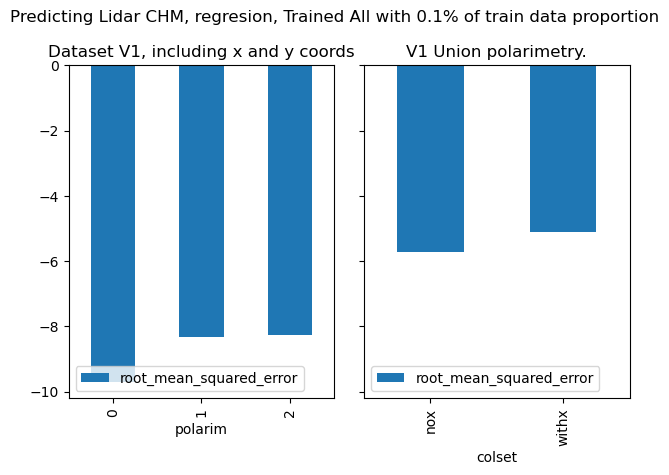

In [20]:
# add title 
import  matplotlib.pyplot as plt 
f, ax = plt.subplots(ncols=2 , sharey=True ) 
ax=ax.ravel() 

df[df['dname']=='v1'][df['colset']=='withx'].plot(x='polarim', y='root_mean_squared_error', kind='bar', ax=ax[0])
ax[0].set_title('Dataset V1, including x and y coords')


df[df['dname']=='v1_unionpol'][df['timelim']!=2500].plot(x='colset', y='root_mean_squared_error', kind='bar', ax=ax[1])
ax[1].set_title('V1 Union polarimetry.')
f.suptitle('Predicting Lidar CHM, regresion, Trained All with 0.1% of train data proportion')
plt.tight_layout()


In [21]:
# estiamte height in each pixel 
# show diff in height 
# lidar, normal plot with esatimaiton, erorrs 
colour stripe 

SyntaxError: invalid syntax (1272799139.py, line 4)

In [ ]:
# want clean version of the data 
# run with L band 

In [ ]:
# add title 
import  matplotlib.pyplot as plt 
f, ax = plt.subplots(ncols=2 , sharey=True ) 
ax=ax.ravel() 

df[df['dname']=='v1'][df['colset']=='withx'].plot(x='polarim', y='r2', kind='bar', ax=ax[0])
ax[0].set_title('Dataset V1, including x and y coords')


df[df['dname']=='v1_unionpol'][df['timelim']!=2500].plot(x='colset', y='r2', kind='bar', ax=ax[1])
ax[1].set_title('V1 Union polarimetry.')
f.suptitle('Predicting Lidar CHM, regresion, Trained All with 0.1% of train data proportion')
plt.tight_layout()


Text(0.5, 1.0, 'Data: union polarimetry. Results for 0.1 of train data')

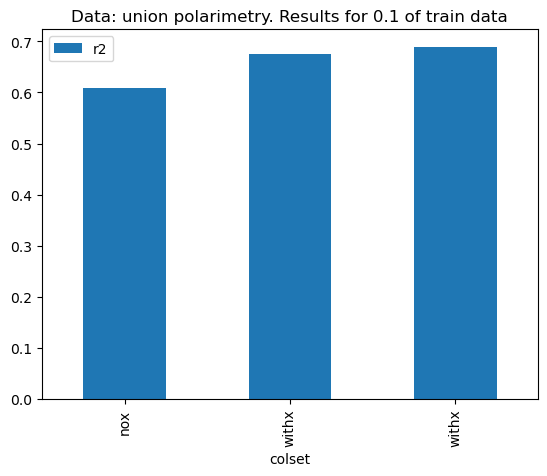

In [ ]:
f, ax=plt.subplots()

df[df['dname']=='v1_unionpol'].plot(x='colset', y='r2', kind='bar', ax=ax)
ax.set_title('Data: union polarimetry. Results for 0.1 of train data')



Text(0.5, 1.0, 'Dataset V1: seperate polarimetry, without x and y coords')

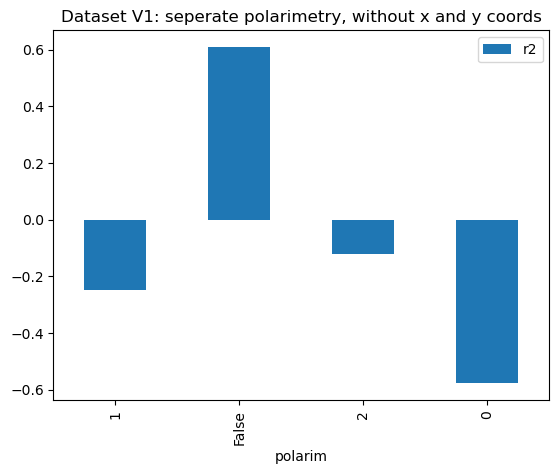

In [ ]:
# add title 
import  matplotlib.pyplot as plt 
f, ax = plt.subplots() 
df[df['colset']!='withx'].plot(x='polarim', y='r2', kind='bar', ax=ax)
ax.set_title('Dataset V1: seperate polarimetry, without x and y coords')